# NumCompute — Quickstart

End-to-end tour of the NumPy-only toolkit:

1. **I/O** – read a CSV with missing values (`io.py`)
2. **Preprocessing** – `SimpleImputer`, `StandardScaler`, `OneHotEncoder` (`preprocessing.py`)
3. **Sorting & searching** – top-k, quickselect, binary search (`sort_search.py`)
4. **Ranking** – tie handling and percentiles (`rank.py`)
5. **Statistics** – mean/variance, histogram, quantiles, streaming Welford (`stats.py`)
6. **Gradients** – finite-difference gradient and Jacobian (`optim.py`)
7. **Pipeline + metrics** – end-to-end model, accuracy/precision/recall/F1, confusion matrix, ROC-AUC
8. **Benchmarks** – vectorised vs Python loops

In [1]:
import os, sys, platform
import numpy as np

# Make the package importable when running from demo/ without `pip install -e .`
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "demo" else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, "benchmark"))

import numcompute as nc
from numcompute import io, preprocessing, sort_search, rank, stats, metrics, optim, pipeline, utils, benchmarking

np.set_printoptions(precision=4, suppress=True)
DATA = os.path.join(ROOT, "demo", "data", "customers.csv")
print("NumCompute", nc.__version__)
for k, v in benchmarking.environment_info().items():
    print(f"{k:>10}: {v}")

NumCompute 1.0.0
    python: 3.14.6
     numpy: 2.4.6
  platform: macOS-14.2-arm64-arm-64bit-Mach-O
   machine: arm64
 processor: arm
 cpu_count: 8


## 1. Reading CSV data (with missing values)

In [2]:
# Numeric columns -> float array, missing cells (empty, NA, ?, null, NaN) -> NaN
X_num, num_cols = io.read_csv(DATA, usecols=["age", "income", "hours_per_week"])
print("numeric shape:", X_num.shape, num_cols)
print("missing per column:", dict(zip(num_cols, io.count_missing(X_num).tolist())))

# Rows with missing values
rows_with_nan = np.flatnonzero(np.isnan(X_num).any(axis=1))
print("rows with missing values:", rows_with_nan)
print(X_num[rows_with_nan[:4]])

numeric shape: (200, 3) ['age', 'income', 'hours_per_week']
missing per column: {'age': 2, 'income': 3, 'hours_per_week': 2}
rows with missing values: [  3  10  25  40  88 120 150]
[[ 40.      nan  28.8 ]
 [   nan  90.6   41.5 ]
 [ 51.   100.79    nan]
 [ 26.      nan  44.9 ]]


In [3]:
# Option A: drop incomplete rows
X_drop, _ = io.read_csv(DATA, usecols=[0, 1, 2], drop_missing=True)
print("after drop_missing:", X_drop.shape)

# Option B: typed columns (numeric vs categorical inferred per column)
cols = io.read_csv_columns(DATA)
print({k: v.dtype for k, v in cols.items()})
X_cat = np.column_stack([cols["city"], cols["plan"]])
y = cols["churn"].astype(int)
print("categorical sample:", X_cat[:3].tolist(), "| class balance:", np.bincount(y))

# Option C: streaming in chunks (constant memory)
print("chunk shapes:", [c.shape for c in io.iter_csv_chunks(DATA, chunksize=64)])

after drop_missing: (193, 3)
{'age': dtype('float64'), 'income': dtype('float64'), 'hours_per_week': dtype('float64'), 'city': dtype('<U9'), 'plan': dtype('<U9'), 'churn': dtype('float64')}
categorical sample: [['Melbourne', 'basic'], ['Perth', 'premium'], ['Brisbane', 'basic']] | class balance: [ 94 106]
chunk shapes: [(64, 6), (64, 6), (64, 6), (8, 6)]


## 2. Preprocessing

In [4]:
imp = preprocessing.SimpleImputer(strategy="median")
X_imp = imp.fit_transform(X_num)
print("imputed medians:", imp.statistics_)

scaler = preprocessing.StandardScaler()
X_std = scaler.fit_transform(X_imp)
print("mean after scaling:", X_std.mean(0), " std:", X_std.std(0))

mm = preprocessing.MinMaxScaler(feature_range=(0, 1))
print("min-max range:", mm.fit_transform(X_imp).min(0), mm.fit_transform(X_imp).max(0))

enc = preprocessing.OneHotEncoder(handle_unknown="ignore")
X_oh = enc.fit_transform(np.where(X_cat == "", "unknown", X_cat))
print("one-hot shape:", X_oh.shape)
print(enc.get_feature_names(["city", "plan"]))

imputed medians: [43.5  75.96 38.6 ]
mean after scaling: [-0. -0. -0.]  std: [1. 1. 1.]
min-max range: [0. 0. 0.] [1. 1. 1.]
one-hot shape: (200, 8)
['city=Brisbane', 'city=Melbourne', 'city=Perth', 'city=Sydney', 'city=unknown', 'plan=basic', 'plan=premium', 'plan=unknown']


## 3. Sorting & searching

In [5]:
income = X_imp[:, 1]
vals, idx = sort_search.topk(income, k=5)                      # argpartition, O(n)
print("top-5 incomes:", vals, "at rows", idx)
vals, idx = sort_search.topk(income, k=3, largest=False)
print("bottom-3 incomes:", vals)

k = len(income) // 2
print("quickselect median-ish:", sort_search.quickselect(income, k), "== np.sort:", np.sort(income)[k])

sorted_inc = sort_search.stable_sort(income)
pos, found = sort_search.binary_search(sorted_inc, sorted_inc[10])
print("binary_search existing ->", pos, found)
pos, found = sort_search.binary_search(sorted_inc, [0.0, 75.0, 1e6])
print("insertion indices:", pos, "found:", found)

# Multi-key sort: by plan (asc) then income (desc)
plan = np.where(cols["plan"] == "", "unknown", cols["plan"])
keys = np.empty((len(plan), 2), dtype=object)       # object array keeps numbers numeric
keys[:, 0], keys[:, 1] = plan, income
order = sort_search.multikey_argsort(keys, keys=[0, 1], descending=[False, True])
print(np.column_stack([plan, np.round(income, 1)])[order][[0, 1, 2, -3, -2, -1]])

top-5 incomes: [126.51 116.56 110.25 108.87 108.55] at rows [ 41 128  92 194 129]
bottom-3 incomes: [30.3  36.42 42.19]
quickselect median-ish: 75.96 == np.sort: 75.96
binary_search existing -> 10 True
insertion indices: [  0  94 200] found: [False False False]
[['basic' '126.5']
 ['basic' '116.6']
 ['basic' '108.9']
 ['premium' '52.1']
 ['premium' '42.2']
 ['unknown' '108.2']]


## 4. Ranking with ties & percentiles

In [6]:
scores = np.array([88, 92, 75, 92, 60, 88, 100])
for m in ["average", "min", "max", "dense", "ordinal"]:
    print(f"{m:>8}:", rank.rank(scores, method=m))
print("descending dense:", rank.rank(scores, "dense", ascending=False))
print("NaN kept:", rank.rank([3.0, np.nan, 1.0]))

 average: [3.5 5.5 2.  5.5 1.  3.5 7. ]
     min: [3 5 2 5 1 3 7]
     max: [4 6 2 6 1 4 7]
   dense: [3 4 2 4 1 3 5]
 ordinal: [3 5 2 6 1 4 7]
descending dense: [3 2 4 2 5 3 1]
NaN kept: [ 2. nan  1.]


In [7]:
for interp in ["linear", "lower", "higher", "midpoint", "nearest"]:
    print(f"{interp:>8} P90 income:", rank.percentile(X_num[:, 1], 90, interp, nan_policy="omit"))
print("quartiles per column:\n", rank.percentile(X_num, [25, 50, 75], axis=0, nan_policy="omit"))
print("matches numpy:", np.allclose(rank.percentile(X_imp, [25, 50, 75], axis=0), np.percentile(X_imp, [25, 50, 75], axis=0)))

  linear P90 income: 96.75200000000001
   lower P90 income: 96.64
  higher P90 income: 96.92
midpoint P90 income: 96.78
 nearest P90 income: 96.64
quartiles per column:
 [[32.    65.92  34.175]
 [43.5   75.96  38.6  ]
 [56.75  86.5   42.475]]
matches numpy: True


## 5. Statistics

In [8]:
print("mean (skipna):", stats.mean(X_num, axis=0, skipna=True))
print("var  (skipna):", stats.var(X_num, axis=0, ddof=1, skipna=True))
print("mean (no skip, NaN propagates):", stats.mean(X_num, axis=0))
print("quantiles 0.1/0.5/0.9 of age:", stats.quantile(X_num[:, 0], [0.1, 0.5, 0.9], skipna=True))

d = stats.describe(X_num)
for key, val in d.items():
    print(f"{key:>9}:", val)

mean (skipna): [43.8838 76.6327 38.2172]
var  (skipna): [205.3113 235.2195  35.9884]
mean (no skip, NaN propagates): [nan nan nan]
quantiles 0.1/0.5/0.9 of age: [23.  43.5 62. ]
    count: [198 197 198]
     mean: [43.8838 76.6327 38.2172]
      std: [14.3287 15.3369  5.999 ]
      min: [18.  30.3 24. ]
      25%: [32.    65.92  34.175]
      50%: [43.5  75.96 38.6 ]
      75%: [56.75  86.5   42.475]
      max: [ 69.   126.51  53.6 ]
n_missing: [2 3 2]


In [9]:
counts, edges = stats.histogram(X_num[:, 1], bins=10)          # NaNs ignored
for c, lo, hi in zip(counts, edges[:-1], edges[1:]):
    print(f"[{lo:6.1f}, {hi:6.1f})  {'#' * int(c):s} {c}")

# Streaming Welford over CSV chunks equals the batch result
rs = stats.RunningStats()
for chunk in io.iter_csv_chunks(DATA, chunksize=50):
    rs.update(chunk[:, :3])
print("streaming mean:", rs.mean, "\nbatch mean:    ", np.nanmean(X_num, 0))
print("streaming var: ", rs.var(ddof=1), "\nbatch var:     ", np.nanvar(X_num, 0, ddof=1))

[  30.3,   39.9)  ## 2
[  39.9,   49.5)  ## 2
[  49.5,   59.2)  ################## 18
[  59.2,   68.8)  ###################################### 38
[  68.8,   78.4)  ##################################################### 53
[  78.4,   88.0)  ######################################### 41
[  88.0,   97.6)  ######################## 24
[  97.6,  107.3)  ########### 11
[ 107.3,  116.9)  ####### 7
[ 116.9,  126.5)  # 1
streaming mean: [43.8838 76.6327 38.2172] 
batch mean:     [43.8838 76.6327 38.2172]
streaming var:  [205.3113 235.2195  35.9884] 
batch var:      [205.3113 235.2195  35.9884]


Matplotlib is building the font cache; this may take a moment.


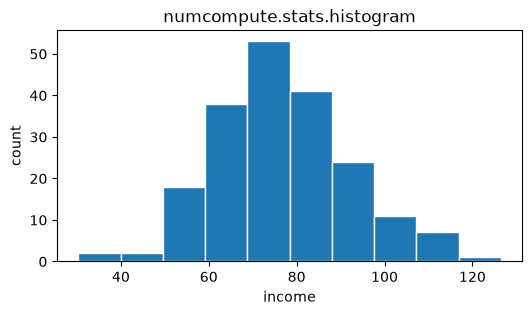

In [10]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", edgecolor="white")
    ax.set_xlabel("income"); ax.set_ylabel("count"); ax.set_title("numcompute.stats.histogram")
    plt.show()
except ImportError:
    print("matplotlib not installed – skipping plot (optional)")

## 6. Finite-difference gradients & Jacobians

In [11]:
f = lambda v: float(v[0] ** 2 + 3 * v[0] * v[1] + np.sin(v[1]))
df = lambda v: np.array([2 * v[0] + 3 * v[1], 3 * v[0] + np.cos(v[1])])
x0 = np.array([1.0, 2.0])
for method in ["central", "forward", "backward"]:
    g = optim.grad(f, x0, method=method)
    print(f"{method:>8}: {g}  |error| = {np.abs(g - df(x0)).max():.2e}")
print("analytic:", df(x0))

F = lambda v: np.array([v[0] * v[1], np.exp(v[0]), v[1] ** 2])
print("Jacobian (3x2):\n", optim.jacobian(F, x0))

# Error vs step size: truncation (large h) vs round-off (small h)
for h in [1e-1, 1e-3, 1e-5, 1e-8, 1e-11]:
    print(f"h={h:.0e}  central err={np.abs(optim.grad(f, x0, h=h) - df(x0)).max():.2e}"
          f"  forward err={np.abs(optim.grad(f, x0, h=h, method='forward') - df(x0)).max():.2e}")

res = optim.gradient_descent(lambda v: float((v[0] - 3) ** 2 + 10 * (v[1] + 1) ** 2), [10.0, 4.0])
print("gradient descent ->", res["x"], "in", res["n_iter"], "iterations")

 central: [8.     2.5839]  |error| = 4.30e-11
 forward: [8.     2.5838]  |error| = 1.00e-05
backward: [8.     2.5839]  |error| = 1.00e-05
analytic: [8.     2.5839]
Jacobian (3x2):
 [[2.     1.    ]
 [2.7183 0.    ]
 [0.     4.    ]]
h=1e-01  central err=2.77e-03  forward err=1.00e-01
h=1e-03  central err=2.77e-07  forward err=1.00e-03
h=1e-05  central err=4.30e-11  forward err=1.00e-05
h=1e-08  central err=1.24e-08  forward err=4.86e-08
h=1e-11  central err=8.91e-06  forward err=8.91e-06
gradient descent -> [ 3. -1.] in 65 iterations


## 7. Pipeline + model + metrics

In [12]:
# Mixed numeric / categorical matrix
X_all = np.empty((len(y), 5), dtype=object)
X_all[:, :3] = X_num
X_all[:, 3] = np.where(cols["city"] == "", "unknown", cols["city"])
X_all[:, 4] = np.where(cols["plan"] == "", "unknown", cols["plan"])

pre = pipeline.ColumnTransformer([
    ("num", pipeline.Pipeline([("impute", preprocessing.SimpleImputer("median")),
                               ("scale", preprocessing.StandardScaler())]), [0, 1, 2]),
    ("cat", preprocessing.OneHotEncoder(handle_unknown="ignore"), [3, 4]),
])
model = pipeline.Pipeline([("prep", pre), ("clf", pipeline.LogisticRegressionGD(lr=0.3, n_iter=800))])

# Simple train/test split
perm = np.random.default_rng(0).permutation(len(y))
tr, te = perm[:150], perm[150:]
model.fit(X_all[tr], y[tr])
y_pred = model.predict(X_all[te])
y_prob = model.predict_proba(X_all[te])[:, 1]
print(model)

Pipeline([
  ('prep', ColumnTransformer(transformers=[('num', Pipeline([
  ('impute', SimpleImputer(strategy='median', fill_value=None)),
  ('scale', StandardScaler(with_mean=True, with_std=True, ddof=0))
]), [0, 1, 2]), ('cat', OneHotEncoder(categories='auto', handle_unknown='ignore', drop_first=False, dtype=<class 'float'>), [3, 4])], remainder='drop')),
  ('clf', LogisticRegressionGD(lr=0.3, n_iter=800, alpha=0.0))
])


In [13]:
print("accuracy :", metrics.accuracy(y[te], y_pred))
print("precision:", metrics.precision(y[te], y_pred))
print("recall   :", metrics.recall(y[te], y_pred))
print("f1       :", metrics.f1(y[te], y_pred))
print("macro f1 :", metrics.f1(y[te], y_pred, average="macro"))
print("confusion matrix (rows=true, cols=pred):\n", metrics.confusion_matrix(y[te], y_pred))
fpr, tpr, thr = metrics.roc_curve(y[te], y_prob)
print("ROC-AUC  :", round(metrics.auc(fpr, tpr), 4))
baseline = pipeline.MajorityClassifier().fit(X_imp[tr], y[tr])
print("majority-class baseline accuracy:", metrics.accuracy(y[te], baseline.predict(X_imp[te])))

# Regression example: predict income from age & hours
reg = pipeline.Pipeline([("scale", preprocessing.StandardScaler()), ("ols", pipeline.LeastSquaresRegressor())])
reg.fit(X_imp[tr][:, [0, 2]], X_imp[tr][:, 1])
print("income MSE:", metrics.mse(X_imp[te][:, 1], reg.predict(X_imp[te][:, [0, 2]])),
      "| R^2:", round(metrics.r2_score(X_imp[te][:, 1], reg.predict(X_imp[te][:, [0, 2]])), 3))

accuracy : 0.64
precision: 0.65625
recall   : 0.75
f1       : 0.7
macro f1 : 0.625
confusion matrix (rows=true, cols=pred):
 [[11 11]
 [ 7 21]]
ROC-AUC  : 0.7305
majority-class baseline accuracy: 0.56
income MSE: 164.58058822564828 | R^2: 0.109


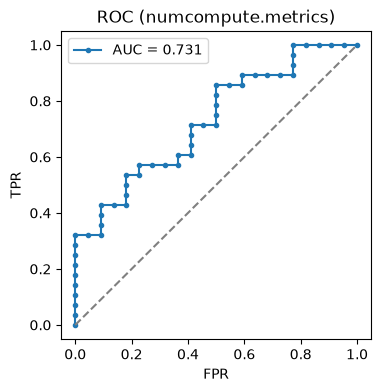

In [14]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.plot(fpr, tpr, marker=".", label=f"AUC = {metrics.auc(fpr, tpr):.3f}")
    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_title("ROC (numcompute.metrics)"); ax.legend()
    plt.show()
except ImportError:
    print("matplotlib not installed – skipping plot (optional)")

## 8. Benchmarks: vectorised vs Python loops

Small inline version of `benchmark/run_benchmarks.py` (run that script for the full table
written to `benchmark/results.md`). Timings: best of 5 runs after one warm-up;
every implementation is checked to return the same result.

In [15]:
import loop_impls as L
rng = np.random.default_rng(0)
Xb = rng.normal(size=(20_000, 8)); Xbl = Xb.tolist()
A, B = rng.normal(size=(300, 16)), rng.normal(size=(200, 16)); Al, Bl = A.tolist(), B.tolist()
xb = rng.normal(size=200_000); xbl = xb.tolist()
yt, yp = rng.integers(0, 5, 100_000), rng.integers(0, 5, 100_000); ytl, ypl = yt.tolist(), yp.tolist()

rows = []
rows += benchmarking.compare({"python loop": lambda: L.standardize_loop(Xbl),
                              "numcompute": lambda: preprocessing.StandardScaler().fit_transform(Xb)}, task="StandardScaler")
rows += benchmarking.compare({"python loop": lambda: L.pairwise_euclidean_loop(Al, Bl),
                              "numcompute": lambda: utils.pairwise_distances(A, B)}, task="Pairwise distances")
rows += benchmarking.compare({"python loop": lambda: L.histogram_loop(xbl, 30),
                              "numcompute": lambda: stats.histogram(xb, 30)[0]}, task="Histogram")
rows += benchmarking.compare({"python sorted()": lambda: L.topk_loop(xbl, 10),
                              "numcompute topk": lambda: sort_search.topk(xb, 10, return_indices=False)}, task="Top-10")
rows += benchmarking.compare({"python loop": lambda: L.confusion_matrix_loop(ytl, ypl, 5),
                              "numcompute": lambda: metrics.confusion_matrix(yt, yp)}, task="Confusion matrix")
print(benchmarking.format_table(rows))

| Task | Implementation | Best (ms) | Mean ± std (ms) | Speed-up |
|---|---|---:|---:|---:|
| StandardScaler | python loop | 30.192 | 30.881 ± 0.468 | 1.0× |
| StandardScaler | numcompute | 1.373 | 1.445 ± 0.049 | 22.0× |
| Pairwise distances | python loop | 87.172 | 87.431 ± 0.219 | 1.0× |
| Pairwise distances | numcompute | 0.168 | 0.307 ± 0.194 | 520.0× |
| Histogram | python loop | 22.453 | 26.411 ± 2.275 | 1.0× |
| Histogram | numcompute | 2.593 | 4.390 ± 2.171 | 8.7× |
| Top-10 | python sorted() | 22.480 | 25.145 ± 3.056 | 1.0× |
| Top-10 | numcompute topk | 0.903 | 0.919 ± 0.017 | 24.9× |
| Confusion matrix | python loop | 3.437 | 3.461 ± 0.027 | 1.0× |
| Confusion matrix | numcompute | 0.328 | 0.361 ± 0.053 | 10.5× |


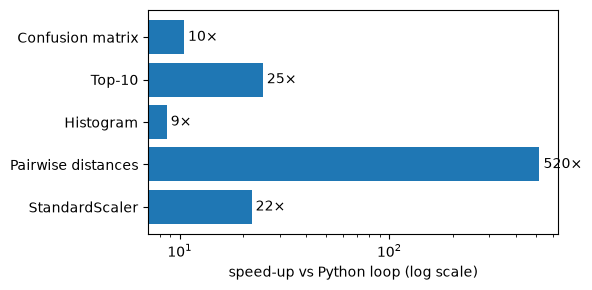

In [16]:
try:
    import matplotlib.pyplot as plt
    tasks = list(dict.fromkeys(r["task"] for r in rows))
    speed = [max(r["speedup"] for r in rows if r["task"] == t) for t in tasks]
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.barh(tasks, speed); ax.set_xscale("log"); ax.set_xlabel("speed-up vs Python loop (log scale)")
    for i, s in enumerate(speed):
        ax.text(s, i, f" {s:.0f}×", va="center")
    plt.tight_layout(); plt.show()
except ImportError:
    pass

## Environment notes

* Only **Python ≥ 3.9 + NumPy ≥ 1.23** are required by the package; `matplotlib` is optional
  and used only for the plots above.
* Benchmark numbers depend on CPU, NumPy build (BLAS/SIMD) and background load —
  re-run the cells (or `python benchmark/run_benchmarks.py`) on your own machine before
  quoting figures in the report.